In [ ]:
import os
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()          #Raw_PPGData.zip
zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name) as z:
    z.extractall("ppg_data")

csv_files = sorted(glob.glob("ppg_data/**/*.csv", recursive=True))
print(len(csv_files), "signal files found")
for f in csv_files[:3]:
    print(f)

Saving Raw_PPGData.zip to Raw_PPGData (2).zip
18 signal files found
ppg_data/Raw_PPGData/signal_01_0001.csv
ppg_data/Raw_PPGData/signal_01_0007.csv
ppg_data/Raw_PPGData/signal_02_0001.csv


In [ ]:
from google.colab import files

uploaded_labels = files.upload()          #labels CSV file
labels_name = list(uploaded_labels.keys())[0]

labels = pd.read_csv(labels_name)

print("File:", labels_name)
print("Rows, columns:", labels.shape)
print("Column names:", list(labels.columns))
labels.head(20)

Saving all_labels - all_labels.csv to all_labels - all_labels (2).csv
File: all_labels - all_labels (2).csv
Rows, columns: (18, 7)
Column names: ['ID', 'Gender', 'Age', 'Glucose', 'Height', 'Weight', 'source']


,ID,Gender,Age,Glucose,Height,Weight,source
0,1,Male,38,99,180,53,label_01_0001
1,2,Male,25,108,187,75,label_02_0001
2,3,Male,33,120,187,103,label_03_0001
3,4,Male,29,100,180,80,label_04_0001
4,5,Male,23,94,175,56,label_05_0001
5,6,Female,31,96,165,60,label_06_0001
6,7,Male,31,88,179,93,label_07_0001
7,8,Male,39,110,165,63,label_08_0001
8,9,Female,25,102,172,60,label_09_0001
9,10,Male,37,106,179,90,label_10_0001


## Data Quality Checking

In this step, we examine the uploaded label dataset to identify missing values, duplicate records and incorrect data types. This helps us understand whether the dataset is suitable for further preprocessing and machine learning.

In [ ]:
# Check dataset information and data types
print("Dataset Information:")
labels.info()

# Check missing values in each column
print("\nMissing Values:")
print(labels.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:",
      labels.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Records:",
      labels.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   ID       18 non-null     int64 
 1   Gender   18 non-null     object
 2   Age      18 non-null     int64 
 3   Glucose  18 non-null     int64 
 4   Height   18 non-null     int64 
 5   Weight   18 non-null     int64 
 6   source   18 non-null     object
dtypes: int64(5), object(2)
memory usage: 1.1+ KB

Missing Values:
ID         0
Gender     0
Age        0
Glucose    0
Height     0
Weight     0
source     0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0


## Exploratory Data Analysis (EDA)

In this step, we perform exploratory data analysis to understand the distribution and statistical characteristics of the dataset. We examine the minimum, maximum, mean and standard deviation of numerical attributes such as Age, Glucose, Height and Weight.

In [ ]:
# Select numerical columns for analysis
numerical_columns = ['Age', 'Glucose', 'Height', 'Weight']

# Generate descriptive statistics
print("Descriptive Statistics of Numerical Features:")
display(labels[numerical_columns].describe())

Descriptive Statistics of Numerical Features:


,Age,Glucose,Height,Weight
count,18.000000,18.000000,18.000000,18.000000
mean,34.333333,110.000000,174.888889,69.388889
std,11.050685,16.197313,9.498538,17.452925
min,22.000000,88.000000,154.000000,42.000000
25%,25.000000,99.000000,166.750000,57.000000
50%,32.000000,107.000000,177.000000,62.500000
75%,38.750000,118.750000,180.000000,82.250000
max,61.000000,146.000000,187.000000,103.000000


In [ ]:
# Analyze Gender distribution
print("Gender Distribution:")
print(labels['Gender'].value_counts())

# Analyze source distribution
print("\nSource Distribution:")
print(labels['source'].value_counts())

Gender Distribution:
Gender
Male      14
Female     4
Name: count, dtype: int64

Source Distribution:
source
label_01_0001    1
label_02_0001    1
label_03_0001    1
label_04_0001    1
label_05_0001    1
label_06_0001    1
label_07_0001    1
label_08_0001    1
label_09_0001    1
label_10_0001    1
label_11_0001    1
label_12_0001    1
label_13_0001    1
label_14_0001    1
label_20_0001    1
label_01_0007    1
label_05_0006    1
label_08_0002    1
Name: count, dtype: int64


## Data Visualization

In this step, we visualize categorical and numerical attributes to understand the distribution of the available records and their glucose measurements. These visualizations provide an overview of the available demographic information and glucose measurements before PPG signal segmentation and feature extraction.

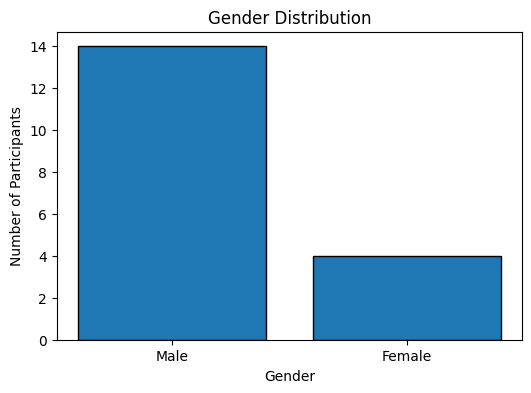

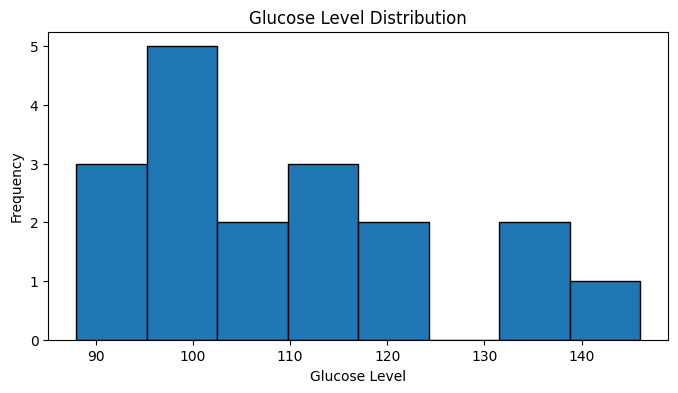

In [ ]:
import matplotlib.pyplot as plt

# Create two separate visualizations

# 1. Gender distribution
plt.figure(figsize=(6, 4))

gender_counts = labels['Gender'].value_counts()

plt.bar(gender_counts.index, gender_counts.values,
        edgecolor='black')

plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Recordings')

plt.show()


# 2. Glucose distribution
plt.figure(figsize=(8, 4))

plt.hist(labels['Glucose'], bins=8, edgecolor='black')

plt.title('Glucose Level Distribution')
plt.xlabel('Glucose Level')
plt.ylabel('Frequency')

plt.show()

In [ ]:
# Check files currently uploaded in Colab
import os

print("Files available in Colab:")
for file in os.listdir('/content'):
    print(file)

Files available in Colab:
.config
classification_comparison_results.csv
Raw_PPGData (2).zip
ppg_data
Raw_PPGData (1).zip
all_labels - all_labels (1).csv
Raw_PPGData.zip
regression_comparison_results.csv
all_labels - all_labels (2).csv
all_labels - all_labels.csv
sample_data


## Inspecting the Raw PPG Dataset

In this step, we inspect the extracted PPG dataset folder to identify the available signal recordings, their file formats and directory structure. This helps us understand how the raw physiological signals are stored before loading them for further processing.

In [ ]:
# Import required library
import os

# Define the PPG dataset directory
ppg_folder = '/content/ppg_data'

# List all files inside the folder and its subfolders
ppg_files = []

for root, dirs, files_list in os.walk(ppg_folder):
    for file in files_list:
        ppg_files.append(os.path.join(root, file))

# Display dataset information
print("Total files found:", len(ppg_files))

print("\nPPG Dataset Files:")
for file in ppg_files:
    print(file)

Total files found: 18

PPG Dataset Files:
/content/ppg_data/Raw_PPGData/signal_05_0006.csv
/content/ppg_data/Raw_PPGData/signal_08_0002.csv
/content/ppg_data/Raw_PPGData/signal_06_0001.csv
/content/ppg_data/Raw_PPGData/signal_10_0001.csv
/content/ppg_data/Raw_PPGData/signal_12_0001.csv
/content/ppg_data/Raw_PPGData/signal_02_0001.csv
/content/ppg_data/Raw_PPGData/signal_13_0001.csv
/content/ppg_data/Raw_PPGData/signal_05_0001.csv
/content/ppg_data/Raw_PPGData/signal_04_0001.csv
/content/ppg_data/Raw_PPGData/signal_11_0001.csv
/content/ppg_data/Raw_PPGData/signal_14_0001.csv
/content/ppg_data/Raw_PPGData/signal_09_0001.csv
/content/ppg_data/Raw_PPGData/signal_03_0001.csv
/content/ppg_data/Raw_PPGData/signal_01_0001.csv
/content/ppg_data/Raw_PPGData/signal_07_0001.csv
/content/ppg_data/Raw_PPGData/signal_20_0001.csv
/content/ppg_data/Raw_PPGData/signal_08_0001.csv
/content/ppg_data/Raw_PPGData/signal_01_0007.csv


## Matching PPG Signals with Label Records

In this step, we establish a relationship between the raw PPG signal recordings and their corresponding participant information in the label dataset. We use the source identifiers to match each signal file with its associated glucose measurement.

This ensures that the correct target value is assigned to each PPG recording before feature extraction and model training.

In [ ]:
# Import required library
import os
import pandas as pd

# Define the PPG dataset folder
ppg_folder = '/content/ppg_data/Raw_PPGData'

# Get all PPG CSV files
signal_csv_files = [
    os.path.join(ppg_folder, file)
    for file in os.listdir(ppg_folder)
    if file.lower().endswith('.csv')
]

# Extract filenames only
available_signals = {
    os.path.basename(file) for file in signal_csv_files
}

# Match label sources with PPG filenames
labels['signal_file'] = labels['source'].apply(
    lambda x: x.replace('label_', 'signal_') + '.csv'
)

# Check matching status
labels['file_exists'] = labels['signal_file'].isin(
    available_signals
)

# Display matching statistics
print("Total Label Records:", len(labels))
print("Total PPG Recordings:", len(signal_csv_files))

print("Successfully Matched:", labels['file_exists'].sum())
print("Missing Signal Files:", (~labels['file_exists']).sum())

# Display mapping table
display(
    labels[['ID', 'Glucose', 'source',
            'signal_file', 'file_exists']]
)

Total Label Records: 18
Total PPG Recordings: 18
Successfully Matched: 18
Missing Signal Files: 0


,ID,Glucose,source,signal_file,file_exists
0,1,99,label_01_0001,signal_01_0001.csv,True
1,2,108,label_02_0001,signal_02_0001.csv,True
2,3,120,label_03_0001,signal_03_0001.csv,True
3,4,100,label_04_0001,signal_04_0001.csv,True
4,5,94,label_05_0001,signal_05_0001.csv,True
5,6,96,label_06_0001,signal_06_0001.csv,True
6,7,88,label_07_0001,signal_07_0001.csv,True
7,8,110,label_08_0001,signal_08_0001.csv,True
8,9,102,label_09_0001,signal_09_0001.csv,True
9,10,106,label_10_0001,signal_10_0001.csv,True


In [ ]:

# RAW PPG SIGNAL QUALITY CHECK

import hashlib

raw_signal_checks = []

for file_path in sorted(signal_csv_files):

    signal_df = pd.read_csv(file_path)
    signal_values = signal_df["signal"]

    signal_hash = hashlib.sha256(
        signal_values.to_numpy().tobytes()
    ).hexdigest()

    raw_signal_checks.append({
        "Filename": os.path.basename(file_path),
        "Samples": len(signal_values),
        "Missing Values": signal_values.isnull().sum(),
        "Data Type": str(signal_values.dtype),
        "Signal Hash": signal_hash
    })

raw_quality_df = pd.DataFrame(raw_signal_checks)

print("RAW PPG DATA QUALITY SUMMARY")
print("--------------------------------")

print("Total Recordings:", len(raw_quality_df))
print(
    "Unique Complete Signals:",
    raw_quality_df["Signal Hash"].nunique()
)
print(
    "Duplicate Recordings:",
    raw_quality_df["Signal Hash"].duplicated().sum()
)
print(
    "Total Missing Values:",
    raw_quality_df["Missing Values"].sum()
)

print("\nIndividual Recording Details:")

display(
    raw_quality_df.drop(columns=["Signal Hash"])
)

print("\nSample Count Distribution:")
display(raw_quality_df["Samples"].value_counts())


RAW PPG DATA QUALITY SUMMARY
--------------------------------
Total Recordings: 18
Unique Complete Signals: 18
Duplicate Recordings: 0
Total Missing Values: 0

Individual Recording Details:


,Filename,Samples,Missing Values,Data Type
0,signal_01_0001.csv,21900,0,int64
1,signal_01_0007.csv,21900,0,int64
2,signal_02_0001.csv,21900,0,int64
3,signal_03_0001.csv,21900,0,int64
4,signal_04_0001.csv,21900,0,int64
5,signal_05_0001.csv,21900,0,int64
6,signal_05_0006.csv,21900,0,int64
7,signal_06_0001.csv,21900,0,int64
8,signal_07_0001.csv,21900,0,int64
9,signal_08_0001.csv,21900,0,int64



Sample Count Distribution:


,count
Samples,
21900,18


## Inspecting the Raw PPG Signal

In this step, we load one PPG recording and examine its dimensions, column names, data types and sample values. We also check for missing values to understand the structure and quality of the raw physiological signal before segmentation and feature extraction.

In [ ]:
# Select the first PPG recording
sample_file = signal_csv_files[0]

# Load the signal
sample_signal = pd.read_csv(sample_file)

# Display filename
print("Selected File:", os.path.basename(sample_file))

# Display dimensions
print("\nSignal Shape:", sample_signal.shape)

# Display column names
print("\nColumn Names:")
print(sample_signal.columns.tolist())

# Display data types
print("\nData Types:")
print(sample_signal.dtypes)

# Display first 10 samples
print("\nFirst 10 Samples:")
display(sample_signal.head(10))

# Check missing values
print("\nMissing Values:")
print(sample_signal.isnull().sum())

Selected File: signal_05_0006.csv

Signal Shape: (21900, 1)

Column Names:
['signal']

Data Types:
signal    int64
dtype: object

First 10 Samples:


,signal
0,496
1,496
2,497
3,496
4,497
5,496
6,496
7,496
8,496
9,496



Missing Values:
signal    0
dtype: int64


## Visualization of Raw PPG Signal

In this step, we visualize the raw Photoplethysmography (PPG) signal to understand its waveform characteristics. The plot helps us observe variations in signal amplitude and identify visible irregularities in the raw recording before segmentation and feature extraction.

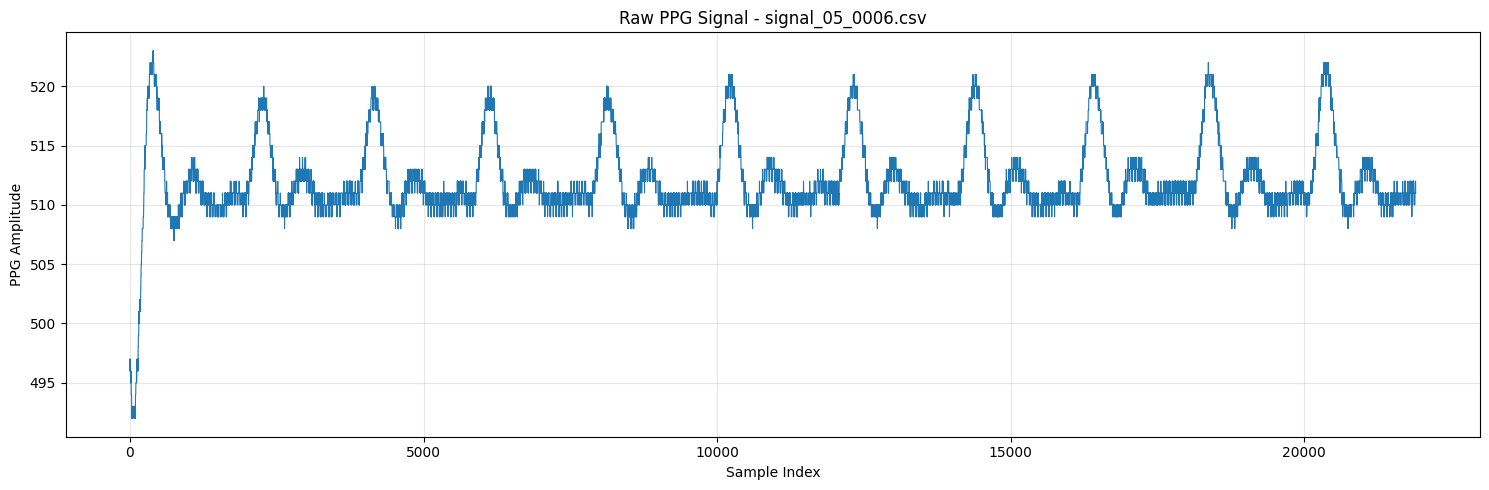

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Extract PPG signal values
ppg_values = sample_signal['signal'].values

# Create sample index
sample_index = np.arange(len(ppg_values))

# Plot raw PPG waveform
plt.figure(figsize=(15, 5))

plt.plot(sample_index, ppg_values, linewidth=0.8)

plt.title(f'Raw PPG Signal - {os.path.basename(sample_file)}')
plt.xlabel('Sample Index')
plt.ylabel('PPG Amplitude')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate basic statistical properties
print("PPG Signal Statistics")

print("Number of Samples:", len(ppg_values))
print("Minimum Amplitude:", np.min(ppg_values))
print("Maximum Amplitude:", np.max(ppg_values))
print("Mean Amplitude:", np.mean(ppg_values))
print("Standard Deviation:", np.std(ppg_values))
print("Signal Range:", np.ptp(ppg_values))

PPG Signal Statistics
Number of Samples: 21900
Minimum Amplitude: 492
Maximum Amplitude: 523
Mean Amplitude: 512.0387214611873
Standard Deviation: 3.321447971921085
Signal Range: 31


## Detailed Visualization of PPG Signal

In this step, we visualize a smaller segment of the raw PPG recording. Zooming into the signal allows us to examine individual waveform patterns, peaks and valleys more clearly. This provides a closer view of the raw signal before segmentation and statistical feature extraction.

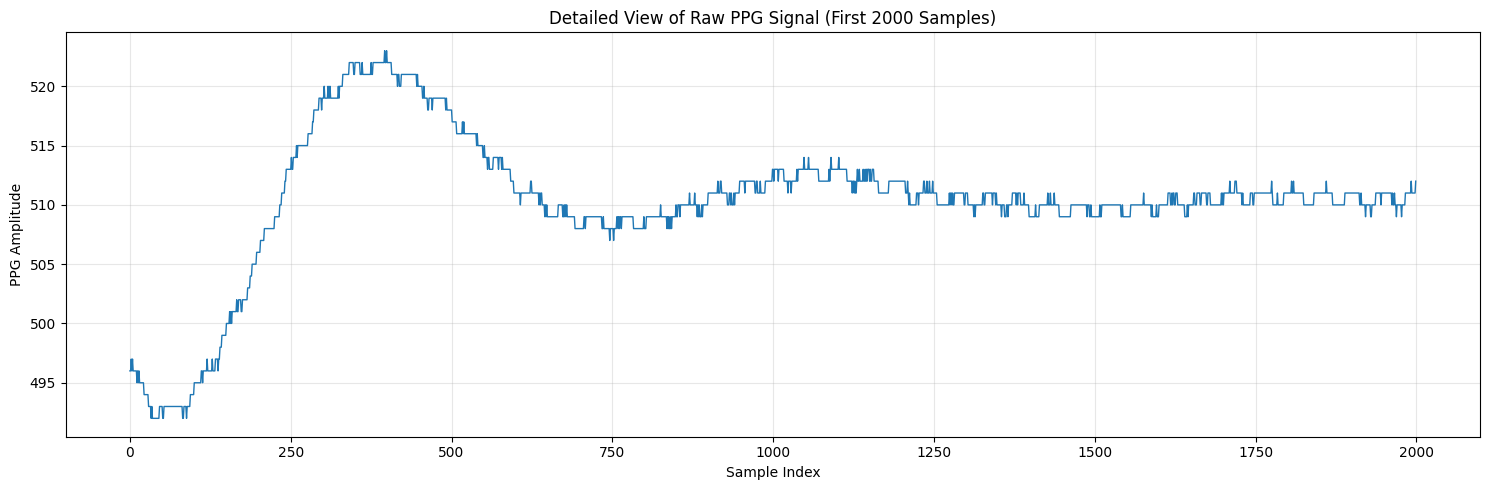

In [ ]:
# Select the first 2000 samples
zoom_samples = 2000

# Plot the selected PPG segment
plt.figure(figsize=(15, 5))

plt.plot(
    sample_index[:zoom_samples],
    ppg_values[:zoom_samples],
    linewidth=1
)

plt.title('Detailed View of Raw PPG Signal (First 2000 Samples)')
plt.xlabel('Sample Index')
plt.ylabel('PPG Amplitude')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Checking Available Sampling Information

In this step, we investigate the available sampling information of the PPG dataset. The sampling frequency is required to convert sample indices into time and to select appropriate digital filter parameters for signal preprocessing. However, the supplied dataset does not provide sufficient information to determine the exact sampling frequency. Therefore, the signals are analyzed using sample indices rather than time in seconds.

In [ ]:
# Check available information about the raw PPG dataset

print("PPG Dataset Folder:")
print(ppg_folder)

print("\nNumber of samples per recording:")
print(len(ppg_values))

print("\nDataset files:")
print(os.listdir('/content'))

print("\nSignal CSV columns:")
print(sample_signal.columns.tolist())

PPG Dataset Folder:
/content/ppg_data/Raw_PPGData

Number of samples per recording:
21900

Dataset files:
['.config', 'classification_comparison_results.csv', 'Raw_PPGData (2).zip', 'ppg_data', 'Raw_PPGData (1).zip', 'all_labels - all_labels (1).csv', 'Raw_PPGData.zip', 'regression_comparison_results.csv', 'all_labels - all_labels (2).csv', 'all_labels - all_labels.csv', 'sample_data']

Signal CSV columns:
['signal']


## Segmentation of Raw PPG Signals

Segmentation is the process of dividing a continuous PPG recording into smaller, fixed-length sections called windows.

In this experiment, three different window sizes (250, 500 and 1000 samples) are considered to investigate how segmentation width affects feature extraction and model performance.

A 50% overlap is maintained between consecutive windows to preserve continuity and capture more signal information.

In [ ]:
# Segment all 18 PPG recordings

import os
import numpy as np
import pandas as pd

# Define experimental window sizes
window_sizes = [250, 500, 1000]

# Use 50% overlap
overlap_ratio = 0.50

# Store segmented signals
segmented_data = {}

# Process each window size
for window_size in window_sizes:

    step_size = int(window_size * (1 - overlap_ratio))

    segments = []

    # Process every recording
    for _, row in labels.iterrows():

        file_path = os.path.join(
            ppg_folder, row['signal_file']
        )

        signal_df = pd.read_csv(file_path)
        signal = signal_df['signal'].values

        # Divide signal into overlapping windows
        segment_index = 0

        for start in range(
            0, len(signal) - window_size + 1, step_size
        ):

            end = start + window_size
            segment = signal[start:end]

            segments.append({
                'ID': row['ID'],
                'Gender': row['Gender'],
                'Age': row['Age'],
                'Glucose': row['Glucose'],
                'source': row['source'],
                'segment_index': segment_index,
                'segment': segment
            })

            segment_index += 1

    segmented_data[window_size] = segments

    print("\nWindow Size:", window_size)
    print("Step Size:", step_size)
    print("Total Segments:", len(segments))
    print("Recordings Processed:", labels.shape[0])

print("\nSegmentation completed successfully.")


Window Size: 250
Step Size: 125
Total Segments: 3132
Recordings Processed: 18

Window Size: 500
Step Size: 250
Total Segments: 1548
Recordings Processed: 18

Window Size: 1000
Step Size: 500
Total Segments: 756
Recordings Processed: 18

Segmentation completed successfully.


In [ ]:
# Display the first few segments for each window size

for window_size, segments in segmented_data.items():

    print("\nWindow Size:", window_size)

    print("First Segment Shape:",
          segments[0]['segment'].shape)

    print("First Segment Glucose:",
          segments[0]['Glucose'])

    print("Total Segments:",
          len(segments))


Window Size: 250
First Segment Shape: (250,)
First Segment Glucose: 99
Total Segments: 3132

Window Size: 500
First Segment Shape: (500,)
First Segment Glucose: 99
Total Segments: 1548

Window Size: 1000
First Segment Shape: (1000,)
First Segment Glucose: 99
Total Segments: 756


## Feature Extraction from Segmented PPG Signals

Feature extraction is the process of converting raw PPG signal segments into meaningful numerical representations.

In this experiment, statistical and amplitude-based features are extracted from each segment. These features will be used as input variables for regression and classification models.

In [ ]:
# Extract features from all PPG segments

from scipy.stats import skew, kurtosis

# Store feature datasets for each window size
feature_datasets = {}

# Extract features for each segmentation experiment
for window_size, segments in segmented_data.items():

    feature_rows = []

    for item in segments:

        signal = item['segment']

        # Calculate statistical features
        features = {
            'ID': item['ID'],
            'Gender': item['Gender'],
            'Age': item['Age'],
            'Glucose': item['Glucose'],
            'source': item['source'],
            'segment_index': item['segment_index'],

            'mean': np.mean(signal),
            'std': np.std(signal),
            'variance': np.var(signal),
            'minimum': np.min(signal),
            'maximum': np.max(signal),
            'median': np.median(signal),
            'range': np.ptp(signal),

            'rms': np.sqrt(np.mean(signal ** 2)),

            'iqr': (
                np.percentile(signal, 75)
                - np.percentile(signal, 25)
            ),

            'skewness': skew(signal),
            'kurtosis': kurtosis(signal),

            'mean_abs_difference': np.mean(
                np.abs(np.diff(signal))
            )
        }

        feature_rows.append(features)

    # Convert extracted features into DataFrame
    feature_df = pd.DataFrame(feature_rows)

    feature_datasets[window_size] = feature_df

    print("\nWindow Size:", window_size)
    print("Feature Dataset Shape:", feature_df.shape)
    print("Extracted Features:", feature_df.shape[1] - 6)

    display(feature_df.head(5))

print("\nFeature extraction completed successfully.")


Window Size: 250
Feature Dataset Shape: (3132, 18)
Extracted Features: 12


,ID,Gender,Age,Glucose,source,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
0,1,Male,38,99,label_01_0001,0,500.048,3.705900,13.733696,495,508,499.0,13,500.061732,6.0,0.497768,-0.951153,0.429719
1,1,Male,38,99,label_01_0001,1,506.716,4.771933,22.771344,497,513,508.0,16,506.738469,8.0,-0.420859,-1.084843,0.453815
2,1,Male,38,99,label_01_0001,2,511.768,1.560185,2.434176,507,514,512.0,7,511.770378,2.0,-1.103103,0.259850,0.469880
3,1,Male,38,99,label_01_0001,3,512.532,0.658009,0.432976,511,514,513.0,3,512.532422,1.0,-0.328528,-0.163149,0.465863
4,1,Male,38,99,label_01_0001,4,512.200,0.692820,0.480000,511,514,512.0,3,512.200469,1.0,-0.072169,-0.541667,0.526104



Window Size: 500
Feature Dataset Shape: (1548, 18)
Extracted Features: 12


,ID,Gender,Age,Glucose,source,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
0,1,Male,38,99,label_01_0001,0,505.908,6.513335,42.423536,495,514,508.0,19,505.949926,13.0,-0.321188,-1.498872,0.450902
1,1,Male,38,99,label_01_0001,1,511.984,1.226272,1.503744,507,514,512.0,7,511.985469,1.0,-1.485801,2.373295,0.498998
2,1,Male,38,99,label_01_0001,2,511.390,1.146255,1.313900,508,514,512.0,6,511.391285,2.0,-0.219501,-0.766649,0.490982
3,1,Male,38,99,label_01_0001,3,509.938,1.003073,1.006156,508,513,510.0,5,509.938987,1.0,0.587946,-0.007025,0.450902
4,1,Male,38,99,label_01_0001,4,509.706,0.841168,0.707564,508,512,510.0,4,509.706694,1.0,0.456137,-0.229904,0.466934



Window Size: 1000
Feature Dataset Shape: (756, 18)
Extracted Features: 12


,ID,Gender,Age,Glucose,source,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
0,1,Male,38,99,label_01_0001,0,508.649,5.420498,29.381799,495,514,511.0,19,508.677881,4.0,-1.340935,0.335765,0.471471
1,1,Male,38,99,label_01_0001,1,510.548,1.311372,1.719696,508,514,510.0,6,510.549684,2.0,0.326475,-0.832738,0.479479
2,1,Male,38,99,label_01_0001,2,513.668,4.965458,24.655776,508,524,511.0,16,513.691999,8.0,0.739964,-1.003857,0.437437
3,1,Male,38,99,label_01_0001,3,512.514,6.157743,37.917804,503,524,511.0,21,512.550991,11.0,0.336587,-1.186059,0.409409
4,1,Male,38,99,label_01_0001,4,508.722,2.306234,5.318716,503,513,509.0,10,508.727228,3.0,-0.673779,-0.634770,0.429429



Feature extraction completed successfully.


In [ ]:
# Verify all feature datasets

for window_size, df in feature_datasets.items():

    print("\nWindow Size:", window_size)

    print("Total Rows:", len(df))

    print("Missing Values:", df.isnull().sum().sum())

    print("Duplicate Rows:", df.duplicated().sum())

    print("\nFeature Summary:")
    display(df.describe().round(3))


Window Size: 250
Total Rows: 3132
Missing Values: 0
Duplicate Rows: 0

Feature Summary:


,ID,Age,Glucose,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
count,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000,3132.000
mean,9.500,34.333,110.000,86.500,512.277,1.539,3.779,508.950,515.562,512.279,6.612,512.281,2.316,0.008,-0.279,0.494
std,5.189,10.741,15.743,50.237,3.210,1.188,7.677,3.284,3.914,3.443,4.179,3.210,2.175,0.453,1.151,0.203
min,1.000,22.000,88.000,0.000,487.568,0.215,0.046,477.000,506.000,484.500,1.000,487.658,0.000,-4.036,-2.000,0.080
25%,5.000,25.000,99.000,43.000,510.580,0.728,0.530,508.000,513.000,510.000,4.000,510.581,1.000,-0.256,-0.805,0.297
50%,9.500,32.000,107.000,86.500,511.604,1.105,1.222,509.000,514.000,512.000,6.000,511.607,2.000,-0.018,-0.436,0.506
75%,14.000,39.000,120.000,130.000,513.496,2.024,4.098,510.000,518.000,513.000,8.000,513.497,3.000,0.243,-0.040,0.651
max,18.000,61.000,146.000,173.000,524.820,11.708,137.073,520.000,530.000,525.000,37.000,524.825,23.000,3.312,17.786,1.032



Window Size: 500
Total Rows: 1548
Missing Values: 0
Duplicate Rows: 0

Feature Summary:


,ID,Age,Glucose,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
count,1548.00,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000,1548.000
mean,9.50,34.333,110.000,42.500,512.310,2.223,8.129,507.995,516.986,512.200,8.991,512.318,3.619,0.139,-0.437,0.494
std,5.19,10.743,15.746,24.832,2.345,1.785,17.420,3.031,4.138,2.455,5.419,2.346,3.642,0.502,1.061,0.200
min,1.00,22.000,88.000,0.000,501.988,0.228,0.052,477.000,509.000,505.000,1.000,502.198,0.000,-1.486,-1.920,0.092
25%,5.00,25.000,99.000,21.000,510.840,0.929,0.864,507.000,514.000,511.000,5.000,510.845,1.000,-0.213,-1.066,0.291
50%,9.50,32.000,107.000,42.500,511.804,1.584,2.510,508.000,516.000,512.000,8.000,511.805,2.000,0.027,-0.579,0.510
75%,14.00,39.000,120.000,64.000,513.637,3.073,9.443,510.000,520.000,513.000,12.000,513.648,5.000,0.371,-0.101,0.655
max,18.00,61.000,146.000,85.000,519.982,16.444,270.402,513.000,530.000,520.000,46.000,520.011,33.250,2.461,16.231,0.998



Window Size: 1000
Total Rows: 756
Missing Values: 0
Duplicate Rows: 0

Feature Summary:


,ID,Age,Glucose,segment_index,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
count,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000,756.000
mean,9.500,34.333,110.000,20.500,512.286,2.845,11.341,507.247,519.103,511.615,11.856,512.297,3.947,0.532,-0.135,0.494
std,5.192,10.746,15.751,12.129,1.498,1.804,16.010,3.756,4.101,1.261,6.106,1.498,2.691,0.593,1.236,0.198
min,1.000,22.000,88.000,0.000,506.823,0.429,0.184,477.000,511.000,508.000,3.000,506.894,0.000,-1.408,-1.573,0.155
25%,5.000,25.000,99.000,10.000,511.303,1.321,1.745,506.000,515.750,511.000,7.000,511.308,2.000,0.180,-0.900,0.284
50%,9.500,32.000,107.000,20.500,512.527,2.601,6.764,508.000,519.000,512.000,11.000,512.549,3.000,0.540,-0.530,0.514
75%,14.000,39.000,120.000,31.000,513.433,3.874,15.012,509.000,522.000,512.250,15.000,513.446,6.000,0.801,0.065,0.658
max,18.000,61.000,146.000,41.000,515.301,13.597,184.869,512.000,530.000,515.000,46.000,515.338,13.000,2.656,6.962,0.929


Regression – Dataset Preparation (Window Size = 1000)

In [ ]:

# STEP 1: PREPARE DATASET FOR REGRESSION
# Window Size = 1000 samples

import pandas as pd
import numpy as np

# Select statistical features
signal_features = [
    'mean', 'std', 'variance', 'minimum',
    'maximum', 'median', 'range', 'rms',
    'iqr', 'skewness', 'kurtosis',
    'mean_abs_difference'
]

# Explicitly select the 1000-sample feature dataset
feature_df = feature_datasets[1000]

# Aggregate segments at recording level
regression_df = feature_df.groupby(
    ['ID', 'Gender', 'Age', 'Glucose', 'source'],
    as_index=False
)[signal_features].mean()

# Display prepared dataset
print("Regression Dataset Information")
print("--------------------------------")
print("Original Segment Rows:", len(feature_df))
print("Recording-Level Rows:", len(regression_df))
print("Number of Unique Subjects:", regression_df['ID'].nunique())

print("\nDataset Shape:", regression_df.shape)

print("\nFirst 5 Records:")
display(regression_df.head())

print("\nMissing Values:")
print(regression_df.isnull().sum().sum())



Regression Dataset Information
--------------------------------
Original Segment Rows: 756
Recording-Level Rows: 18
Number of Unique Subjects: 18

Dataset Shape: (18, 17)

First 5 Records:


,ID,Gender,Age,Glucose,source,mean,std,variance,minimum,maximum,median,range,rms,iqr,skewness,kurtosis,mean_abs_difference
0,1,Male,38,99,label_01_0001,511.936167,3.823196,17.282610,506.190476,520.738095,510.642857,14.547619,511.953020,5.190476,0.637407,-0.041438,0.431884
1,2,Male,25,108,label_02_0001,511.141548,4.392898,22.686979,504.238095,521.619048,509.928571,17.380952,511.163728,5.726190,0.726294,-0.153156,0.544807
2,3,Male,33,120,label_03_0001,511.503119,4.355369,24.910004,505.619048,521.738095,509.690476,16.119048,511.527397,6.029762,0.795469,0.326468,0.447638
3,4,Male,29,100,label_04_0001,511.912714,2.575113,8.725867,506.571429,518.595238,511.190476,12.023810,511.921234,3.642857,0.632768,0.217484,0.645741
4,5,Male,23,94,label_05_0001,512.097857,2.924119,10.956592,506.666667,519.714286,511.238095,13.047619,512.108547,3.988095,0.681278,0.086895,0.698961



Missing Values:
0


Regression – Model Training and Performance Evaluation

In [ ]:


# STEP 2: REGRESSION MODEL TRAINING

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Input features and target glucose values
X_signal = regression_df[signal_features]
X_demographic = regression_df[signal_features + ['Age', 'Gender']]
y = regression_df['Glucose']

# Leave-One-Out Cross Validation
loo = LeaveOneOut()

# Define the four required regression models
models = {
    'Linear Regression': LinearRegression(),

    'SVR': SVR(
        kernel='rbf',
        C=10,
        epsilon=5
    ),

    'Decision Tree Regressor': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )
}

# Store experimental results
results = []

# Evaluate models with and without demographic features
for feature_type in ['PPG Only', 'PPG + Age + Gender']:

    print("\nFeature Configuration:", feature_type)

    if feature_type == 'PPG Only':
        X = X_signal.copy()
        numeric_columns = signal_features
        categorical_columns = []
    else:
        X = X_demographic.copy()
        numeric_columns = signal_features + ['Age']
        categorical_columns = ['Gender']

    # Preprocessing
    transformers = [
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_columns)
    ]

    if categorical_columns:
        transformers.append(
            ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
        )

    preprocessor = ColumnTransformer(transformers)

    for model_name, model in models.items():

        pipeline = Pipeline([
            ('preprocessing', preprocessor),
            ('model', model)
        ])

        # Predict each recording using the other recordings
        predictions = cross_val_predict(
            pipeline, X, y, cv=loo
        )

        mae = mean_absolute_error(y, predictions)
        mse = mean_squared_error(y, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y, predictions)

        results.append({
            'Features': feature_type,
            'Model': model_name,
            'MAE': mae,
            'MSE': mse,
            'RMSE': rmse,
            'R2 Score': r2
        })

        print("\nModel:", model_name)
        print("MAE:", round(mae, 3))
        print("MSE:", round(mse, 3))
        print("RMSE:", round(rmse, 3))
        print("R2 Score:", round(r2, 3))

# Final comparison table
regression_results = pd.DataFrame(results)

print("\nFINAL REGRESSION COMPARISON")
display(regression_results.round(3))




Feature Configuration: PPG Only

Model: Linear Regression
MAE: 44.994
MSE: 3585.116
RMSE: 59.876
R2 Score: -13.469

Model: SVR
MAE: 13.879
MSE: 316.91
RMSE: 17.802
R2 Score: -0.279

Model: Decision Tree Regressor
MAE: 18.5
MSE: 483.833
RMSE: 21.996
R2 Score: -0.953

Model: Random Forest Regressor
MAE: 15.573
MSE: 355.712
RMSE: 18.86
R2 Score: -0.436

Feature Configuration: PPG + Age + Gender

Model: Linear Regression
MAE: 60.842
MSE: 5883.621
RMSE: 76.705
R2 Score: -22.746

Model: SVR
MAE: 14.237
MSE: 328.004
RMSE: 18.111
R2 Score: -0.324

Model: Decision Tree Regressor
MAE: 20.278
MSE: 566.722
RMSE: 23.806
R2 Score: -1.287

Model: Random Forest Regressor
MAE: 15.496
MSE: 366.4
RMSE: 19.142
R2 Score: -0.479

FINAL REGRESSION COMPARISON


,Features,Model,MAE,MSE,RMSE,R2 Score
0,PPG Only,Linear Regression,44.994,3585.116,59.876,-13.469
1,PPG Only,SVR,13.879,316.910,17.802,-0.279
2,PPG Only,Decision Tree Regressor,18.500,483.833,21.996,-0.953
3,PPG Only,Random Forest Regressor,15.573,355.712,18.860,-0.436
4,PPG + Age + Gender,Linear Regression,60.842,5883.621,76.705,-22.746
5,PPG + Age + Gender,SVR,14.237,328.004,18.111,-0.324
6,PPG + Age + Gender,Decision Tree Regressor,20.278,566.722,23.806,-1.287
7,PPG + Age + Gender,Random Forest Regressor,15.496,366.400,19.142,-0.479



## Comparative Regression Analysis Using Different Segmentation Widths

In this experiment, four regression models are evaluated using three different PPG segmentation widths: 250, 500 and 1000 samples.

The extracted segment-level features are aggregated at the recording level so that each recording contributes one observation after segment-level features are aggregated.

The four regression models are Linear Regression, Support Vector Regressor (SVR), Decision Tree Regressor and Random Forest Regressor.

Each model is evaluated using PPG-only features and a combination of PPG and demographic features (Age and Gender).

Leave-One-Out Cross-Validation is used for evaluation. Performance is compared using MAE, MSE, RMSE and R² Score.


In [ ]:

# COMPARE ALL SEGMENTATION WIDTHS

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define extracted PPG features
signal_features = [
    'mean', 'std', 'variance', 'minimum',
    'maximum', 'median', 'range', 'rms',
    'iqr', 'skewness', 'kurtosis',
    'mean_abs_difference'
]

# Define the four required regression models
models = {
    'Linear Regression': LinearRegression(),

    'SVR': SVR(
        kernel='rbf',
        C=10,
        epsilon=5
    ),

    'Decision Tree Regressor': DecisionTreeRegressor(
        random_state=42
    ),

    'Random Forest Regressor': RandomForestRegressor(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )
}

# Leave-one-recording-out evaluation
loo = LeaveOneOut()

# Store all experiment results
all_regression_results = []

# Test each segmentation width
for window_size in [250, 500, 1000]:

    print("\n" + "=" * 55)
    print("SEGMENTATION WIDTH:", window_size)
    print("=" * 55)

    # Get feature dataset for current window
    current_df = feature_datasets[window_size].copy()

    # Aggregate segment features by recording
    participant_df = current_df.groupby(
        ['ID', 'Gender', 'Age', 'Glucose', 'source'],
        as_index=False
    )[signal_features].mean()

    y = participant_df['Glucose']

    # Compare two feature configurations
    for feature_type in ['PPG Only', 'PPG + Age + Gender']:

        if feature_type == 'PPG Only':

            X = participant_df[signal_features]
            numeric_columns = signal_features
            categorical_columns = []

        else:

            X = participant_df[
                signal_features + ['Age', 'Gender']
            ]

            numeric_columns = signal_features + ['Age']
            categorical_columns = ['Gender']

        # Prepare preprocessing pipeline
        transformers = [
            ('numeric', Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]), numeric_columns)
        ]

        if categorical_columns:
            transformers.append(
                ('categorical', OneHotEncoder(
                    handle_unknown='ignore'
                ), categorical_columns)
            )

        preprocessor = ColumnTransformer(transformers)

        # Evaluate each regression model
        for model_name, model in models.items():

            pipeline = Pipeline([
                ('preprocessing', preprocessor),
                ('model', model)
            ])

            predictions = cross_val_predict(
                pipeline, X, y, cv=loo
            )

            mae = mean_absolute_error(y, predictions)
            mse = mean_squared_error(y, predictions)
            rmse = np.sqrt(mse)
            r2 = r2_score(y, predictions)

            all_regression_results.append({
                'Window Size': window_size,
                'Features': feature_type,
                'Model': model_name,
                'MAE': mae,
                'MSE': mse,
                'RMSE': rmse,
                'R2 Score': r2
            })

            print(
                feature_type, "|", model_name,
                "| MAE:", round(mae, 3),
                "| RMSE:", round(rmse, 3),
                "| R2:", round(r2, 3)
            )

# Create final results DataFrame
all_regression_results = pd.DataFrame(
    all_regression_results
)

print("\nFINAL COMPARISON OF ALL REGRESSION EXPERIMENTS")

display(
    all_regression_results.round(3)
)




SEGMENTATION WIDTH: 250
PPG Only | Linear Regression | MAE: 35.898 | RMSE: 58.507 | R2: -12.815
PPG Only | SVR | MAE: 13.417 | RMSE: 17.392 | R2: -0.221
PPG Only | Decision Tree Regressor | MAE: 21.111 | RMSE: 25.43 | R2: -1.61
PPG Only | Random Forest Regressor | MAE: 14.254 | RMSE: 18.246 | R2: -0.344
PPG + Age + Gender | Linear Regression | MAE: 49.954 | RMSE: 74.668 | R2: -21.501
PPG + Age + Gender | SVR | MAE: 13.941 | RMSE: 17.864 | R2: -0.288
PPG + Age + Gender | Decision Tree Regressor | MAE: 19.5 | RMSE: 23.531 | R2: -1.235
PPG + Age + Gender | Random Forest Regressor | MAE: 15.185 | RMSE: 18.786 | R2: -0.424

SEGMENTATION WIDTH: 500
PPG Only | Linear Regression | MAE: 35.334 | RMSE: 44.923 | R2: -7.145
PPG Only | SVR | MAE: 14.129 | RMSE: 18.006 | R2: -0.309
PPG Only | Decision Tree Regressor | MAE: 22.5 | RMSE: 26.912 | R2: -1.923
PPG Only | Random Forest Regressor | MAE: 15.116 | RMSE: 19.033 | R2: -0.462
PPG + Age + Gender | Linear Regression | MAE: 43.624 | RMSE: 57.927 

,Window Size,Features,Model,MAE,MSE,RMSE,R2 Score
0,250,PPG Only,Linear Regression,35.898,3423.059,58.507,-12.815
1,250,PPG Only,SVR,13.417,302.483,17.392,-0.221
2,250,PPG Only,Decision Tree Regressor,21.111,646.667,25.430,-1.610
3,250,PPG Only,Random Forest Regressor,14.254,332.930,18.246,-0.344
4,250,PPG + Age + Gender,Linear Regression,49.954,5575.323,74.668,-21.501
5,250,PPG + Age + Gender,SVR,13.941,319.127,17.864,-0.288
6,250,PPG + Age + Gender,Decision Tree Regressor,19.500,553.722,23.531,-1.235
7,250,PPG + Age + Gender,Random Forest Regressor,15.185,352.897,18.786,-0.424
8,500,PPG Only,Linear Regression,35.334,2018.050,44.923,-7.145
9,500,PPG Only,SVR,14.129,324.224,18.006,-0.309


In [ ]:
# Compare the models based on MAE

best_regression = all_regression_results.loc[
    all_regression_results['MAE'].idxmin()
]

print("Best Regression Configuration")
print("--------------------------------")

print("Window Size:", best_regression['Window Size'])
print("Features:", best_regression['Features'])
print("Model:", best_regression['Model'])
print("MAE:", round(best_regression['MAE'], 3))
print("RMSE:", round(best_regression['RMSE'], 3))
print("R2 Score:", round(best_regression['R2 Score'], 3))

Best Regression Configuration
--------------------------------
Window Size: 250
Features: PPG Only
Model: SVR
MAE: 13.417
RMSE: 17.392
R2 Score: -0.221


In [ ]:
# SAVE REGRESSION EXPERIMENT RESULTS

# Save all regression configurations
all_regression_results.to_csv(
    'regression_comparison_results.csv',
    index=False
)

print("Regression results saved successfully!")

# Display best-performing configuration based on MAE
best_regression = all_regression_results.loc[
    all_regression_results['MAE'].idxmin()
]

print("\nBest Regression Configuration")
print("--------------------------------")
print(best_regression)

# Download results
from google.colab import files

files.download('regression_comparison_results.csv')


Regression results saved successfully!

Best Regression Configuration
--------------------------------
Window Size           250
Features         PPG Only
Model                 SVR
MAE              13.41652
MSE            302.482626
RMSE            17.392028
R2 Score        -0.220782
Name: 1, dtype: object


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In this stage, glucose values are converted into categorical labels using the project-defined glucose thresholds. Classification is performed independently using the actual glucose measurements, not the predictions generated by the regression models. The three segmentation widths are retained for comparison.

In [ ]:

import numpy as np
import pandas as pd

# Define glucose categories
def assign_glucose_category(glucose):
    if glucose <= 125:
        return "Normal"
    elif glucose <= 175:
        return "Prediabetic"
    else:
        return "Diabetic"

# Create a copy of recording-level regression dataset
classification_labels = regression_df[
    ["ID", "Glucose"]
].copy()

# Assign category using actual glucose values
classification_labels["Glucose_Category"] = (
    classification_labels["Glucose"].apply(assign_glucose_category)
)

# Display recording-level labels
print("Recording Glucose Categories")
display(classification_labels)

# Display class distribution
print("\nClass Distribution")
display(
    classification_labels["Glucose_Category"]
    .value_counts()
    .reindex(["Normal", "Prediabetic", "Diabetic"], fill_value=0)
)


Recording Glucose Categories


,ID,Glucose,Glucose_Category
0,1,99,Normal
1,2,108,Normal
2,3,120,Normal
3,4,100,Normal
4,5,94,Normal
5,6,96,Normal
6,7,88,Normal
7,8,110,Normal
8,9,102,Normal
9,10,106,Normal



Class Distribution


,count
Glucose_Category,
Normal,15
Prediabetic,3
Diabetic,0


The extracted PPG features are aggregated at the recording level for each segmentation width. Each recording is assigned a binary glucose category based on its actual glucose measurement. The resulting datasets are used independently for classification experiments.

In [ ]:

# Prepare classification datasets for all window sizes

classification_datasets = {}

for window_size in [250, 500, 1000]:

    # Get extracted features for this window size
    temp_df = feature_datasets[window_size].copy()

    # Aggregate segment-level features for each recording
    participant_df = temp_df.groupby(
        ["ID", "Gender", "Age", "Glucose", "source"],
        as_index=False
    )[signal_features].mean()

    # Assign binary glucose categories
    participant_df["Glucose_Category"] = (
        participant_df["Glucose"].apply(assign_glucose_category)
    )
    # Store the prepared dataset
    classification_datasets[window_size] = participant_df

    print(f"\nWindow Size: {window_size}")
    print("Dataset Shape:", participant_df.shape)

    print("\nClass Distribution:")
    print(participant_df["Glucose_Category"].value_counts())

    print("\nMissing Values:", participant_df.isnull().sum().sum())

print("\nAll classification datasets prepared successfully!")



Window Size: 250
Dataset Shape: (18, 18)

Class Distribution:
Glucose_Category
Normal         15
Prediabetic     3
Name: count, dtype: int64

Missing Values: 0

Window Size: 500
Dataset Shape: (18, 18)

Class Distribution:
Glucose_Category
Normal         15
Prediabetic     3
Name: count, dtype: int64

Missing Values: 0

Window Size: 1000
Dataset Shape: (18, 18)

Class Distribution:
Glucose_Category
Normal         15
Prediabetic     3
Name: count, dtype: int64

Missing Values: 0

All classification datasets prepared successfully!



## Classification Model Training and Performance Evaluation

Four machine learning classifiers are evaluated using Leave-One-Out Cross-Validation (LOOCV).

The classifiers include Logistic Regression, Support Vector Machine (SVC), Decision Tree Classifier and Random Forest Classifier.

StandardScaler is applied within each training fold to prevent data leakage.

The models are evaluated using Accuracy, Macro Precision, Macro Recall, Macro F1-score and Balanced Accuracy. Confusion matrices are also generated to examine the classification performance.

Since the dataset contains only Normal and Prediabetic glucose categories, the classification experiment is performed as a binary classification task. These categories are based on project-defined thresholds and should not be interpreted as a medical diagnosis.


In [ ]:


# CLASSIFICATION MODEL TRAINING

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Use only the 12 PPG features
X_columns = signal_features

# Fixed category order for evaluation
class_names = ["Normal", "Prediabetic"]

# Leave-One-Out Cross-Validation
loo = LeaveOneOut()

# Define the four required classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "SVM (SVC)": SVC(
        kernel="rbf",
        C=1,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree Classifier": DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest Classifier": RandomForestClassifier(
        n_estimators=200,
        max_depth=3,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    )
}

classification_results = []
classification_predictions = {}

# Experiment with all three window sizes
for window_size, data in classification_datasets.items():

    X = data[X_columns]
    y = data["Glucose_Category"]

    print("\n" + "=" * 60)
    print("WINDOW SIZE:", window_size)
    print("=" * 60)

    for model_name, model in models.items():

        # Scaling is fitted separately inside each CV fold
        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", model)
        ])

        # Generate one prediction for every recording
        predictions = cross_val_predict(
            pipeline,
            X,
            y,
            cv=loo
        )

        # Calculate evaluation metrics
        accuracy = accuracy_score(y, predictions)

        precision = precision_score(
            y, predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y, predictions,
            average="macro",
            zero_division=0
        )

        f1 = f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(y, predictions)

        # Store results
        classification_results.append({
            "Window Size": window_size,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Balanced Accuracy": balanced_acc
        })

        # Store predictions for confusion matrices
        classification_predictions[(window_size, model_name)] = predictions

        print(f"\nModel: {model_name}")
        print("Confusion Matrix:")
        print(confusion_matrix(
            y, predictions,
            labels=class_names
        ))

# Create final results table
classification_results_df = pd.DataFrame(classification_results)

print("\n\nFINAL CLASSIFICATION COMPARISON")

display(
    classification_results_df.sort_values(
        by=["F1 Score", "Balanced Accuracy"],
        ascending=False
    ).round(4)
)



WINDOW SIZE: 250

Model: Logistic Regression
Confusion Matrix:
[[10  5]
 [ 3  0]]

Model: SVM (SVC)
Confusion Matrix:
[[11  4]
 [ 3  0]]

Model: Decision Tree Classifier
Confusion Matrix:
[[8 7]
 [3 0]]

Model: Random Forest Classifier
Confusion Matrix:
[[14  1]
 [ 3  0]]

WINDOW SIZE: 500

Model: Logistic Regression
Confusion Matrix:
[[9 6]
 [3 0]]

Model: SVM (SVC)
Confusion Matrix:
[[9 6]
 [3 0]]

Model: Decision Tree Classifier
Confusion Matrix:
[[7 8]
 [3 0]]

Model: Random Forest Classifier
Confusion Matrix:
[[14  1]
 [ 3  0]]

WINDOW SIZE: 1000

Model: Logistic Regression
Confusion Matrix:
[[9 6]
 [3 0]]

Model: SVM (SVC)
Confusion Matrix:
[[9 6]
 [3 0]]

Model: Decision Tree Classifier
Confusion Matrix:
[[9 6]
 [3 0]]

Model: Random Forest Classifier
Confusion Matrix:
[[13  2]
 [ 3  0]]


FINAL CLASSIFICATION COMPARISON


,Window Size,Model,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy
3,250,Random Forest Classifier,0.7778,0.4118,0.4667,0.4375,0.4667
7,500,Random Forest Classifier,0.7778,0.4118,0.4667,0.4375,0.4667
11,1000,Random Forest Classifier,0.7222,0.4062,0.4333,0.4194,0.4333
1,250,SVM (SVC),0.6111,0.3929,0.3667,0.3793,0.3667
0,250,Logistic Regression,0.5556,0.3846,0.3333,0.3571,0.3333
4,500,Logistic Regression,0.5000,0.3750,0.3000,0.3333,0.3000
5,500,SVM (SVC),0.5000,0.3750,0.3000,0.3333,0.3000
8,1000,Logistic Regression,0.5000,0.3750,0.3000,0.3333,0.3000
9,1000,SVM (SVC),0.5000,0.3750,0.3000,0.3333,0.3000
10,1000,Decision Tree Classifier,0.5000,0.3750,0.3000,0.3333,0.3000


In [ ]:
# Save classification comparison results

classification_results_df.to_csv(
    'classification_comparison_results.csv',
    index=False
)

print("Classification results saved successfully!")

# Download results
from google.colab import files

files.download('classification_comparison_results.csv')

Classification results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>